### Imported libraries and load data 

In [1]:
import pandas as pd

In [2]:
import numpy as np
import matplotlib.pyplot as plt

In [3]:
sales = pd.read_csv("../Data/raw/m5-forecasting-accuracy/sales_train_validation.csv")
calendar= pd.read_csv("../Data/raw/m5-forecasting-accuracy/calendar.csv")
Prices= pd.read_csv("../Data/raw/m5-forecasting-accuracy/sell_prices.csv")

In [4]:
print("Sales:", sales.shape)
print("Calendar:", calendar.shape)
print("Prices:", Prices.shape)

Sales: (30490, 1919)
Calendar: (1969, 14)
Prices: (6841121, 4)


In [5]:
sales.describe()

,d_1,d_2,d_3,d_4,d_5,d_6,d_7,d_8,d_9,d_10,...,d_1904,d_1905,d_1906,d_1907,d_1908,d_1909,d_1910,d_1911,d_1912,d_1913
count,30490.000000,30490.000000,30490.000000,30490.000000,30490.000000,30490.000000,30490.000000,30490.000000,30490.000000,30490.000000,...,30490.000000,30490.000000,30490.000000,30490.000000,30490.000000,30490.000000,30490.000000,30490.000000,30490.000000,30490.000000
mean,1.070220,1.041292,0.780026,0.833454,0.627944,0.958052,0.918662,1.244080,1.073663,0.838701,...,1.370581,1.586159,1.693670,1.248245,1.232207,1.159167,1.149000,1.328862,1.605838,1.633158
std,5.126689,5.365468,3.667454,4.415141,3.379344,4.785947,5.059495,6.617729,5.917204,4.206199,...,3.740017,4.097191,4.359809,3.276925,3.125471,2.876026,2.950364,3.358012,4.089422,3.812248
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,1.000000,2.000000,2.000000,1.000000,1.000000,1.000000,1.000000,1.000000,2.000000,2.000000
max,360.000000,436.000000,207.000000,323.000000,296.000000,314.000000,316.000000,370.000000,385.000000,353.000000,...,129.000000,160.000000,204.000000,98.000000,100.000000,88.000000,77.000000,141.000000,171.000000,130.000000


### Convert sales data into a time-series format

#### Converted the sales dataset from wide format to long format using melt().

In [6]:
sales_columns = [
    col for col in sales.columns
    if col.startswith("d_")
]

sales_long = sales.melt(  # melt() converts columns into rows.
    id_vars=[             #columns we want to keep unchanged.
        "id",
        "item_id",
        "dept_id",
        "cat_id",
        "store_id",
        "state_id"
    ],
    value_vars=sales_columns, 
    var_name="d",            # name of the new column containing the original column names.
    value_name="sales"      #name of the new column containing their values.
)

sales_long.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d,sales
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0


In [7]:
print(f"Sales dataset memory: {sales.memory_usage(deep=True).sum() / 1024**2:.2f} MB") # Just checking up my pc memory for the further taks 

Sales dataset memory: 455.38 MB


In [8]:
import psutil

ram = psutil.virtual_memory()

print(f"Total RAM: {ram.total / 1024**3:.2f} GB")
print(f"Available RAM: {ram.available / 1024**3:.2f} GB")

Total RAM: 15.70 GB
Available RAM: 4.87 GB


In [9]:
print(f"Sales memory: {sales.memory_usage(deep=True).sum() / 1024**3:.2f} GB")

Sales memory: 0.44 GB


In [10]:
print("Shape:", sales_long.shape)
print(
    f"Memory usage: "
    f"{sales_long.memory_usage(deep=True).sum() / 1024**3:.2f} GB"
)

Shape: (58327370, 8)
Memory usage: 22.78 GB


In [11]:
sales_long.head()

,id,item_id,dept_id,cat_id,store_id,state_id,d,sales
0,HOBBIES_1_001_CA_1_validation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
1,HOBBIES_1_002_CA_1_validation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
2,HOBBIES_1_003_CA_1_validation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
3,HOBBIES_1_004_CA_1_validation,HOBBIES_1_004,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0
4,HOBBIES_1_005_CA_1_validation,HOBBIES_1_005,HOBBIES_1,HOBBIES,CA_1,CA,d_1,0


In [12]:
sales_long.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58327370 entries, 0 to 58327369
Data columns (total 8 columns):
 #   Column    Dtype 
---  ------    ----- 
 0   id        object
 1   item_id   object
 2   dept_id   object
 3   cat_id    object
 4   store_id  object
 5   state_id  object
 6   d         object
 7   sales     int64 
dtypes: int64(1), object(7)
memory usage: 3.5+ GB


### Merging calendar data on sales 

In [13]:
sales_long = sales_long.merge(
    calendar[["d", "date", "weekday", "event_name_1", "event_type_1"]],
    on="d",
    how="left"
)

In [14]:
sales_long[["item_id", "store_id", "d", "date", "sales", "weekday"]].head(10)

,item_id,store_id,d,date,sales,weekday
0,HOBBIES_1_001,CA_1,d_1,2011-01-29,0,Saturday
1,HOBBIES_1_002,CA_1,d_1,2011-01-29,0,Saturday
2,HOBBIES_1_003,CA_1,d_1,2011-01-29,0,Saturday
3,HOBBIES_1_004,CA_1,d_1,2011-01-29,0,Saturday
4,HOBBIES_1_005,CA_1,d_1,2011-01-29,0,Saturday
5,HOBBIES_1_006,CA_1,d_1,2011-01-29,0,Saturday
6,HOBBIES_1_007,CA_1,d_1,2011-01-29,0,Saturday
7,HOBBIES_1_008,CA_1,d_1,2011-01-29,12,Saturday
8,HOBBIES_1_009,CA_1,d_1,2011-01-29,2,Saturday
9,HOBBIES_1_010,CA_1,d_1,2011-01-29,0,Saturday


### CHECKED MISSING VALUES

In [18]:
print("Missing dates:", sales_long["date"].isna().sum())
print("Missing weekdays:", sales_long["weekday"].isna().sum())

Missing dates: 0
Missing weekdays: 0


In [16]:
weekday_demand = (
    sales_long.groupby("weekday")["sales"]
    .mean()
    .sort_values(ascending=False)
)

print(weekday_demand)

weekday
Saturday     1.362640
Sunday       1.348968
Friday       1.122531
Monday       1.077500
Tuesday      0.996024
Thursday     0.990653
Wednesday    0.984258
Name: sales, dtype: float64


### SATURDAY has the highest avg_sales 1.362640

### PLOTTED A GRAPH AVG DAILY SALES by weekdays

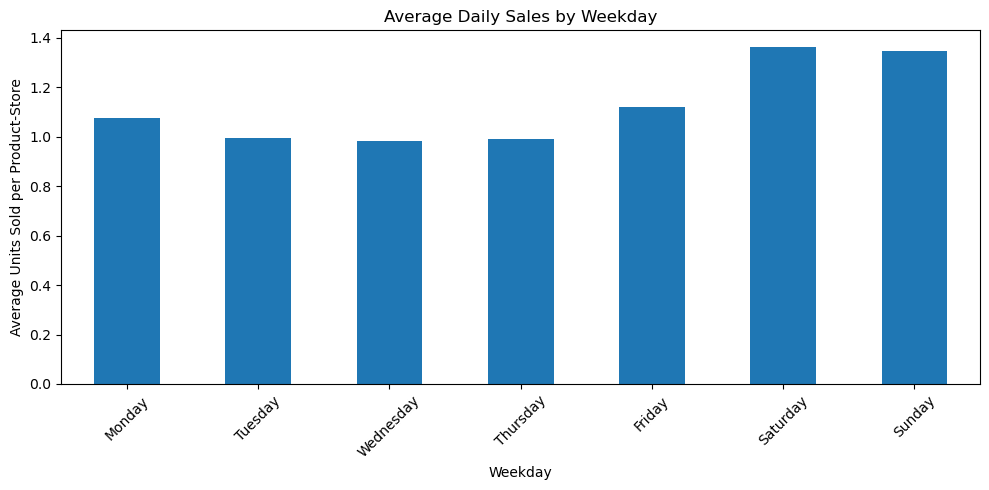

In [22]:
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

weekday_demand = (
    sales_long.groupby("weekday")["sales"]
    .mean()
    .reindex(weekday_order)
)

plt.figure(figsize=(10, 5))
weekday_demand.plot(kind="bar")

plt.title("Average Daily Sales by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average Units Sold per Product-Store")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("AVG_SALES_WEEKDAY.png",dpi=300,bbox_inches="tight")
plt.show()